# 01 — Exploration et préparation des données

**Question de recherche.** *Les catastrophes d'origine climatique (inondations, tempêtes, sécheresses, canicules, feux) subies par un pays une année donnée réduisent-elles sa croissance économique, et de combien ?*

**Tâche d'apprentissage.** Régression supervisée : prédire la croissance annuelle du PIB réel (%) d'un pays $i$ l'année $t$ à partir de son exposition aux catastrophes climatiques (années $t$ et $t-1$) et de variables de contrôle macroéconomiques.

**Critère de succès.** (i) Le modèle doit battre des références naïves (moyenne, persistance) sur un test *postérieur* à l'entraînement ; (ii) l'ajout des variables « catastrophes » doit améliorer l'erreur hors échantillon par rapport à un modèle de contrôle seul — c'est le test direct de la question ; (iii) les effets estimés doivent être stables (intervalles de confiance par bootstrap).

**Données (Kaggle).**
| Jeu | URL Kaggle | Source originale | Contenu |
|---|---|---|---|
| Catastrophes naturelles 1900–2021 | https://www.kaggle.com/datasets/brsdincer/all-natural-disasters-19002021-eosdis | EM-DAT (CRED, UCLouvain) | 1 ligne = 1 catastrophe : pays, année, type, morts, sinistrés, dommages (k USD) |
| PIB mondial | https://www.kaggle.com/datasets/zgrcemta/world-gdpgdp-gdp-per-capita-and-annual-growths | Banque mondiale (WDI) | PIB courant, PIB/hab, croissance du PIB réel, 1960–2020 |

In [1]:
import os, sys, time, warnings
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # métriques autorisées
from src import data_prep as dp
from src.plot_style import *
setup()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
import seaborn as sns

## 1. Données brutes EM-DAT

In [2]:
dis = dp.load_disasters()
print(dis.shape)
dis[["Year", "Country", "ISO", "Disaster Type", "Total Deaths", "Total Affected", dp.DMG_COL]].sample(5, random_state=SEED)

(14644, 47)


,Year,Country,ISO,Disaster Type,Total Deaths,Total Affected,Total Damages ('000 US$)
4965,1997,Russian Federation (the),RUS,Wildfire,14.0,NaN,NaN
12449,2016,Korea (the Democratic People's Republic of),PRK,Flood,538.0,667715.0,61000.0
6363,2002,Chile,CHL,Extreme temperature,NaN,25000.0,NaN
8882,2006,Chad,TCD,Epidemic,20.0,216.0,NaN
8294,2006,China,CHN,Flood,42.0,10009.0,11000.0


In [3]:
dis["group"] = dis["Disaster Type"].map(dp.CLIMATE_GROUPS)
dis.loc[dis["Disaster Type"].isin(dp.GEO_TYPES), "group"] = "geo"
print(dis["group"].value_counts(dropna=False))   # NaN = épidémies, insectes... exclus

group
hydro      5987
meteo      4005
NaN        2115
geo        1400
climato    1137
Name: count, dtype: int64


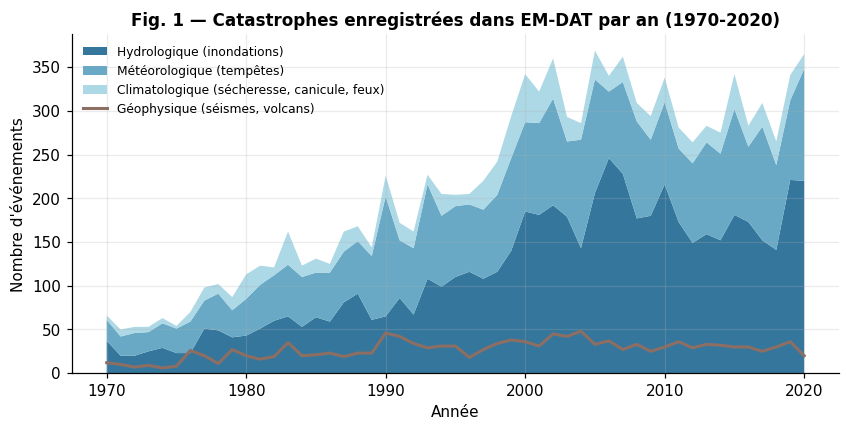

In [4]:
labels = {"hydro": "Hydrologique (inondations)", "meteo": "Météorologique (tempêtes)",
          "climato": "Climatologique (sécheresse, canicule, feux)", "geo": "Géophysique (séismes, volcans)"}
cnt = dis[dis.group.notna()].pivot_table(index="Year", columns="group", values="Dis No", aggfunc="count").fillna(0)
cnt = cnt[cnt.index <= 2020]
fig, ax = plt.subplots(figsize=(9, 4))
ax.stackplot(cnt.index, cnt["hydro"], cnt["meteo"], cnt["climato"],
             labels=[labels[g] for g in ["hydro", "meteo", "climato"]],
             colors=["#2a6f97", "#61a5c2", "#a9d6e5"], alpha=0.95)
ax.plot(cnt.index, cnt["geo"], color=C_GEO, lw=2, label=labels["geo"])
ax.set(title="Fig. 1 — Catastrophes enregistrées dans EM-DAT par an (1970-2020)",
       xlabel="Année", ylabel="Nombre d'événements")
ax.legend(loc="upper left", fontsize=8)
save(fig, "fig01_disasters_per_year.png"); plt.show()

Le nombre d'événements **climatiques** est multiplié par ~5 entre 1970 et 2000, alors que les catastrophes **géophysiques** restent stables. Une partie de la hausse est réelle (réchauffement, urbanisation des zones exposées), mais une partie vient de l'amélioration de l'enregistrement : c'est l'un des biais majeurs du jeu de données, discuté dans le rapport.

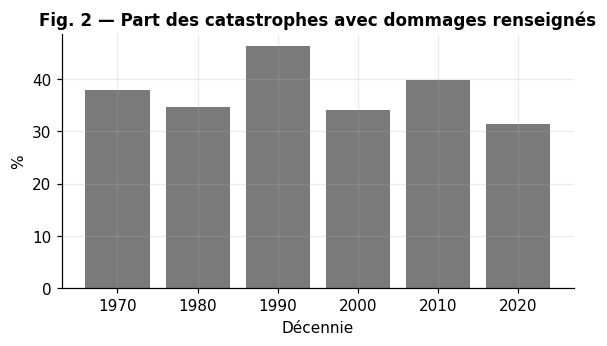

decade
1970    37.9
1980    34.8
1990    46.3
2000    34.1
2010    39.9
2020    31.5
Name: Total Damages ('000 US$), dtype: float64

In [5]:
dis["decade"] = (dis.Year // 10) * 10
miss = dis[dis.group.notna()].groupby("decade")[dp.DMG_COL].apply(lambda s: s.notna().mean() * 100)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(miss.index.astype(str), miss.values, color=C_NEUTRAL)
ax.set(title="Fig. 2 — Part des catastrophes avec dommages renseignés", xlabel="Décennie", ylabel="%")
save(fig, "fig02_damage_reporting.png"); plt.show()
miss.round(1)

Seules ~30-40 % des catastrophes ont un montant de dommages renseigné. **Traitement des valeurs manquantes** : un montant manquant est compté comme 0 dans l'agrégat pays-année. C'est une hypothèse forte (sous-estimation des dommages, surtout dans les pays pauvres), que nous compensons partiellement en ajoutant des variables toujours renseignées : nombre d'événements, morts et sinistrés rapportés à la population.

## 2. Construction du panel pays-année
`src/data_prep.py` :
1. agrège les catastrophes par (pays ISO, année) : dommages, morts, sinistrés, nombre d'événements par groupe ;
2. fusionne avec la Banque mondiale ; les pays-années sans catastrophe reçoivent 0 ;
3. normalise par la taille du pays : dommages en **% du PIB**, morts **par million d'habitants**, sinistrés en **% de la population** (population = PIB / PIB par habitant) ;
4. applique $\log(1+x)$ aux variables très asymétriques ;
5. crée les retards ($t-1$) en vérifiant que l'année précédente existe bien ;
6. ajoute la croissance mondiale de l'année (ligne `WLD`) comme contrôle du cycle global.

In [6]:
panel = dp.build_panel()
os.makedirs("../data/processed", exist_ok=True)
panel.to_csv("../data/processed/panel.csv", index=False)
print(f"{len(panel)} observations, {panel.ISO.nunique()} pays, {panel.year.min()}-{panel.year.max()}")
panel[dp.FEATURES + [dp.TARGET]].describe().T[["mean", "std", "min", "50%", "max"]]

8093 observations, 201 pays, 1971-2020


,mean,std,min,50%,max
log_dmg_climate_pct,0.091,0.387,0.000,0.000,5.639
log_dmg_climate_pct_lag1,0.092,0.393,0.000,0.000,5.639
log_deaths_climate_pm,0.382,0.841,0.000,0.000,8.970
log_affected_climate_pct,0.281,0.725,0.000,0.000,4.807
n_hydro,0.679,1.518,0.000,0.000,26.000
n_meteo,0.450,1.505,0.000,0.000,27.000
n_climato,0.127,0.428,0.000,0.000,9.000
log_dmg_geo_pct,0.015,0.169,0.000,0.000,4.574
growth_lag1,3.691,6.215,-64.047,3.771,149.973
log_gdppc_lag1,7.809,1.641,2.998,7.723,11.724


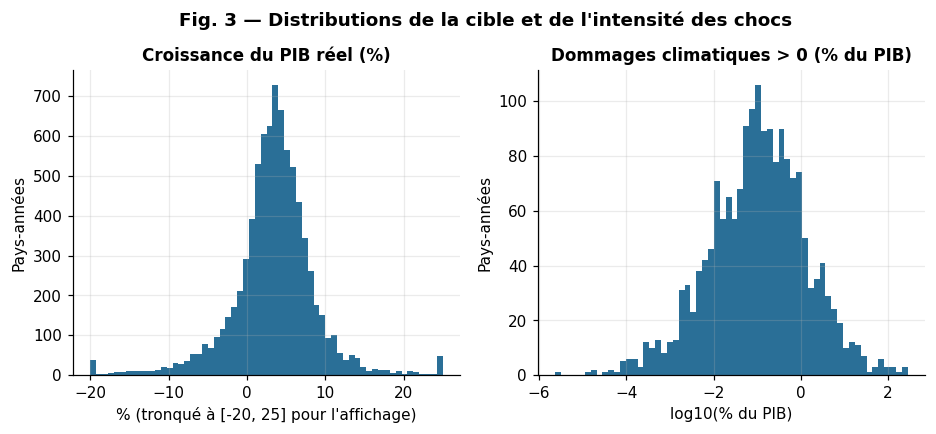

Pays-années avec dommages climatiques > 0 : 22.0%
... > 1 % du PIB : 3.7%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(panel.gdp_growth.clip(-20, 25), bins=60, color=C_SCRATCH)
axes[0].set(title="Croissance du PIB réel (%)", xlabel="% (tronqué à [-20, 25] pour l'affichage)", ylabel="Pays-années")
pos = panel.loc[panel.dmg_climate_pct > 0, "dmg_climate_pct"]
axes[1].hist(np.log10(pos), bins=60, color=C_CLIMATE)
axes[1].set(title="Dommages climatiques > 0 (% du PIB)", xlabel="log10(% du PIB)", ylabel="Pays-années")
fig.suptitle("Fig. 3 — Distributions de la cible et de l'intensité des chocs", fontweight="bold", y=1.03)
save(fig, "fig03_distributions.png"); plt.show()
print(f"Pays-années avec dommages climatiques > 0 : {(panel.dmg_climate_pct > 0).mean():.1%}")
print(f"... > 1 % du PIB : {(panel.dmg_climate_pct > 1).mean():.1%}")

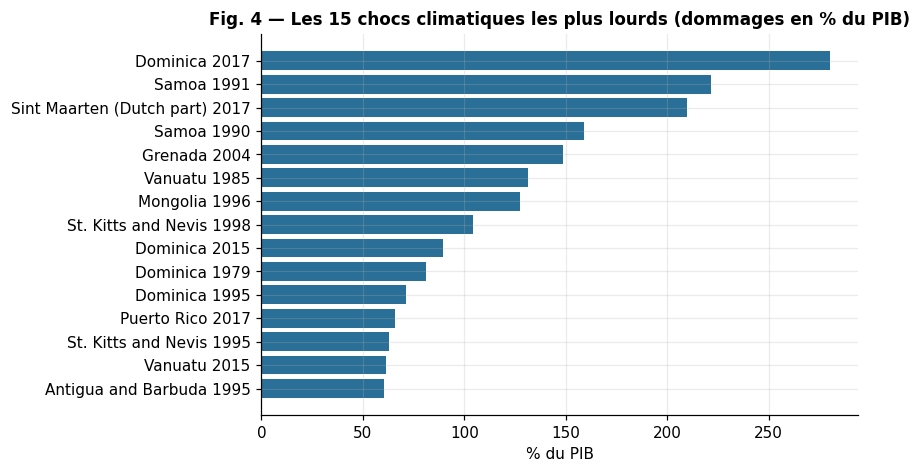

In [8]:
top = panel.nlargest(15, "dmg_climate_pct")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.country + " " + top.year.astype(str), top.dmg_climate_pct, color=C_CLIMATE)
ax.invert_yaxis()
ax.set(title="Fig. 4 — Les 15 chocs climatiques les plus lourds (dommages en % du PIB)", xlabel="% du PIB")
save(fig, "fig04_top_shocks.png"); plt.show()

Les chocs les plus lourds touchent presque tous de **petits États insulaires** (Caraïbes, Pacifique) frappés par des cyclones : un seul ouragan peut détruire plus que le PIB annuel (Dominique 2017, ouragan Maria : 280 %).

## 3. Relation brute entre chocs et croissance

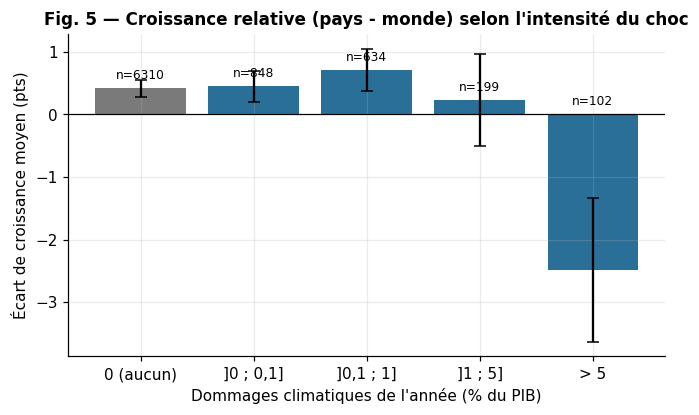

,mean,std,count,ci
bucket,,,,
0 (aucun),0.418,5.627,6310,0.139
"]0 ; 0,1]",0.447,3.623,848,0.244
"]0,1 ; 1]",0.705,4.362,634,0.340
]1 ; 5],0.234,5.281,199,0.734
> 5,-2.480,5.924,102,1.150


In [9]:
df = panel.copy()
df["gap"] = df.gdp_growth.clip(-30, 30) - df.world_growth          # croissance relative au cycle mondial
bins = [-np.inf, 0, 0.1, 1, 5, np.inf]
names = ["0 (aucun)", "]0 ; 0,1]", "]0,1 ; 1]", "]1 ; 5]", "> 5"]
df["bucket"] = pd.cut(df.dmg_climate_pct, bins=bins, labels=names)
g = df.groupby("bucket", observed=True)["gap"].agg(["mean", "std", "count"])
g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(g.index.astype(str), g["mean"], yerr=g["ci"], capsize=4,
       color=[C_NEUTRAL] + [C_CLIMATE] * 4)
for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
    ax.text(i, 0.15 if m < 0 else m + 0.15, f"n={n}", ha="center", fontsize=8)
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Fig. 5 — Croissance relative (pays - monde) selon l'intensité du choc",
       xlabel="Dommages climatiques de l'année (% du PIB)", ylabel="Écart de croissance moyen (pts)")
save(fig, "fig05_growth_by_bucket.png"); plt.show()
g

### Étude d'événement
Pour chaque choc majeur (dommages ≥ 1 % du PIB), on suit l'écart de croissance du pays à sa propre moyenne de long terme de $t-2$ à $t+3$. Ce graphique purement descriptif motive l'introduction d'un effet retardé ($t-1$) dans les modèles.

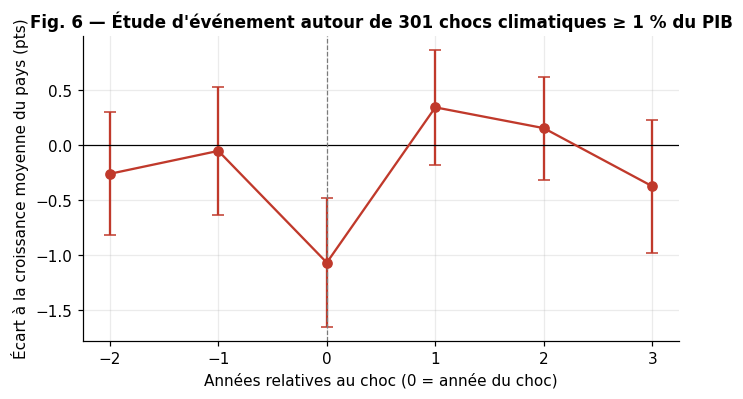

,k,mean,ci,n
0,-2,-0.261,0.559,290
1,-1,-0.052,0.582,296
2,0,-1.067,0.583,301
3,1,0.343,0.524,295
4,2,0.154,0.468,292
5,3,-0.374,0.602,289


In [10]:
df["dev"] = df.gdp_growth.clip(-30, 30) - df.groupby("ISO").gdp_growth.transform(lambda s: s.clip(-30, 30).mean())
idx = df.set_index(["ISO", "year"])["dev"]
events = df.loc[df.dmg_climate_pct >= 1, ["ISO", "year"]]
offsets = range(-2, 4)
rows = []
for k in offsets:
    vals = [idx.get((iso, y + k), np.nan) for iso, y in events.itertuples(index=False)]
    vals = np.array(vals, float); vals = vals[~np.isnan(vals)]
    rows.append((k, vals.mean(), 1.96 * vals.std(ddof=1) / np.sqrt(len(vals)), len(vals)))
es = pd.DataFrame(rows, columns=["k", "mean", "ci", "n"])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(es.k, es["mean"], yerr=es["ci"], marker="o", color=C_ACCENT, capsize=4)
ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color=C_NEUTRAL, ls="--", lw=0.8)
ax.set(title=f"Fig. 6 — Étude d'événement autour de {len(events)} chocs climatiques ≥ 1 % du PIB",
       xlabel="Années relatives au choc (0 = année du choc)", ylabel="Écart à la croissance moyenne du pays (pts)")
save(fig, "fig06_event_study.png"); plt.show()
es

## 4. Découpage temporel et prévention des fuites de données

* **Train** : 1971–2005 · **Validation** : 2006–2012 (choix des hyperparamètres) · **Test** : 2013–2019 (évaluation finale, utilisé une seule fois) · **2020** : année COVID, isolée comme *stress test* (choc mondial hors distribution).
* Découpage **chronologique** et non aléatoire : un découpage aléatoire mélangerait des années futures dans l'entraînement et surestimerait la performance (autocorrélation des séries de croissance).
* Les bornes de **winsorisation** (1er et 99e centiles de la croissance, pour neutraliser guerres et boom pétroliers : −64 % à +150 %) et les paramètres de **standardisation** (moyenne, écart-type) sont estimés **sur le train uniquement** puis appliqués aux autres échantillons.
* Les retards ($t-1$) n'utilisent que de l'information disponible avant l'année prédite. La croissance mondiale de l'année $t$ est une variable contemporaine : elle sert de contrôle explicatif (on ne fait pas de prévision opérationnelle).

train     5174
val       1359
test      1371
stress     189
Name: n, dtype: int64
Bornes de winsorisation (train) : {'gdp_growth': (-13.48, 21.34), 'growth_lag1': (-13.96, 21.8)}


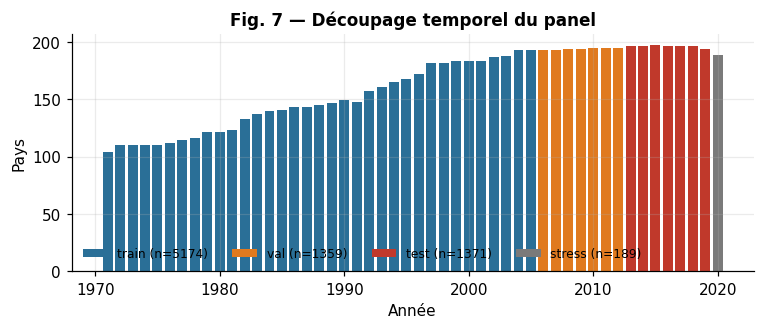

In [11]:
s = dp.make_splits(panel)
sizes = pd.Series({k: len(v) for k, v in s.frames.items()}, name="n")
print(sizes); print("Bornes de winsorisation (train) :", {k: tuple(round(x, 2) for x in v) for k, v in s.clip.items()})
cols = {"train": C_SCRATCH, "val": C_SKLEARN, "test": C_ACCENT, "stress": C_NEUTRAL}
fig, ax = plt.subplots(figsize=(8, 2.8))
for k, f in s.frames.items():
    c = f.year.value_counts().sort_index(); ax.bar(c.index, c.values, color=cols[k], label=f"{k} (n={len(f)})")
ax.set(title="Fig. 7 — Découpage temporel du panel", xlabel="Année", ylabel="Pays")
ax.legend(ncol=4, fontsize=8, loc="lower left")
save(fig, "fig07_splits.png"); plt.show()

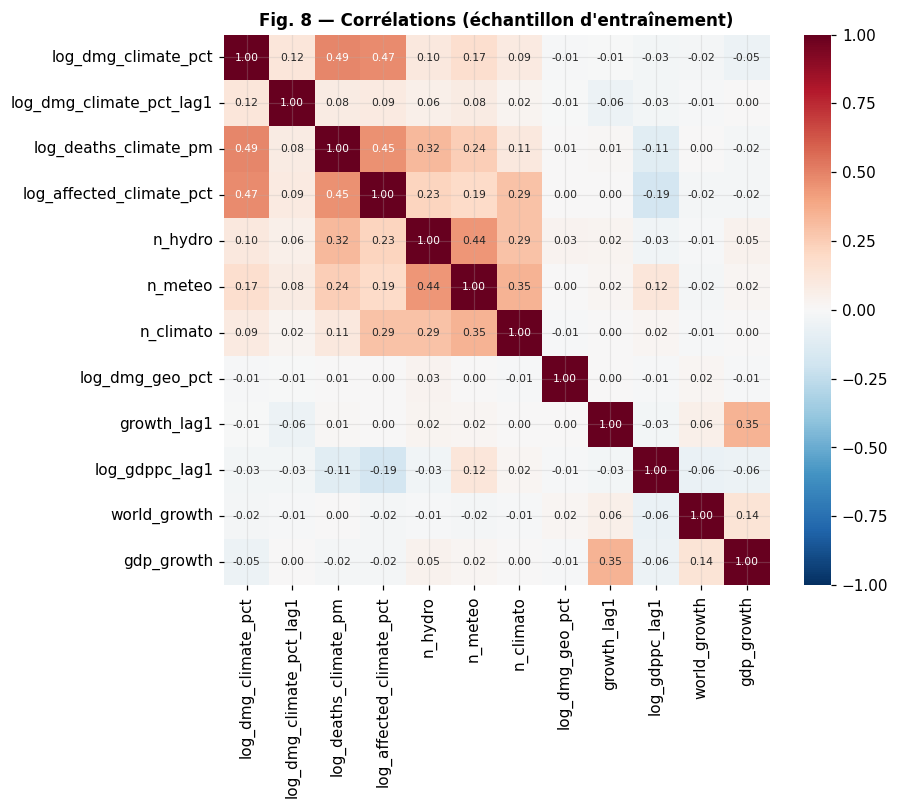

In [12]:
corr = s.frames["train"][dp.FEATURES + [dp.TARGET]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Fig. 8 — Corrélations (échantillon d'entraînement)")
save(fig, "fig08_correlations.png"); plt.show()

**À retenir.** Les corrélations linéaires brutes entre chocs et croissance sont faibles (|ρ| < 0,1) : la croissance dépend surtout de son inertie (`growth_lag1`) et du cycle mondial. Les variables de catastrophes sont corrélées entre elles (dommages / morts / sinistrés), ce qui justifie de tester une pénalisation Ridge. On s'attend donc à un gain de prédiction **modeste mais mesurable** en ajoutant les catastrophes — c'est ce que les notebooks 02 et 03 quantifient.